# Lab: Relationships in Space and Time

Select **two distinct datasets that each contain both spatial and temporal information**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of Plotly Express figures for each question**, for a total of two research questions and four figures.

Together, each pair of figures must help answer where and when the pattern occurs. A map and a time-series plot are one useful combination; other combinations are welcome when you explain how they address both space and time.

## Learning goals

- Select and document datasets with usable location and time features.
- Ask focused questions that connect a measurement or event count to both space and time.
- Prepare dates, geographic identifiers, and summaries appropriately for the question.
- Create and compare two complementary interactive figures for each question.
- Check plotted values and ordering against the records.
- Support conclusions with evidence and explain the limitations of the data and displays.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.

## Select your two datasets

Each dataset needs:

- A documented publisher and feature definitions or data dictionary.
- A usable **time feature**, such as a timestamp, date, month, or year, with observations from multiple times.
- A usable **spatial feature**, such as coordinates, station locations, or named geographic areas with matching identifiers, covering multiple places or a moving object's locations.
- A quantitative measurement with known units, or event records that support a meaningful count.
- Enough usable observations to compare places and periods. A file with dates from one fixed location alone will not support a spatial comparison.

Use two distinct datasets, not two filters of the same file. Choose your own questions and records rather than reproducing a worked lecture example. The suggestions below are starting points, not required choices. You may select another documented source.

Choose manageable geographic and time ranges before downloading. A country or city name does not automatically provide coordinates; document any station lookup, geographic-code lookup, or boundary file you need. Save fixed copies in this notebook's `data` folder, preserve the original records, and use relative paths. Include supporting lookup files with your submission.

### Candidate datasets

| Candidate and source | Useful spatial and time information | Possible question and figure pair |
| --- | --- | --- |
| [USGS earthquake catalog](https://earthquake.usgs.gov/earthquakes/search/) and [CSV field definitions](https://earthquake.usgs.gov/earthquakes/feed/v1.0/csv.php) | Event time, coordinates, magnitude, and depth. Limit the dates, geographic bounds, and magnitude range; download CSV. | Where did recorded earthquakes cluster during a selected period, and how did monthly counts change? Use a point or density map and a monthly count plot. |
| [NOAA daily weather observations](https://www.ncei.noaa.gov/cdo-web/search) and [GHCNd documentation](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily) | Station identifiers, dates, temperature or precipitation, and documented station locations. Select several stations and the same time span. | How did monthly precipitation differ among selected locations during a year? Use a station map of monthly summaries and a line plot or location-by-month heatmap. |
| [EPA daily air-quality data](https://www.epa.gov/outdoor-air-quality-data/download-daily-data) and [file documentation](https://aqs.epa.gov/aqsweb/airdata/download_files.html) | Monitor or county identifiers, dates, pollutant measurements or AQI. Use one pollutant and compatible units; obtain station coordinates if making a point map. | Where and when were PM2.5 concentrations highest among selected monitors? Use a map and a time-series plot grouped by monitor. |
| [NOAA Storm Events Database](https://www.ncei.noaa.gov/access/storm-events-database/) | Event dates, states/counties, event types, and locations when reported. Start with one event type, a few states, and a limited period. | How did reported hail-event counts vary across selected counties and months? Use a county choropleth and a county-by-month heatmap. County boundaries/codes are needed for the map. |

Adapt the question to the fields actually available. Counts of reported events or monitor observations can reflect reporting and sampling effort as well as the underlying phenomenon. Do not treat missing observations as zero events or average measurements with incompatible units.

## Choose two complementary figures per question

Choose **different chart types**, not two copies that differ only in color, title, filter, or static-versus-animated display. You may reuse a useful chart type with the second dataset. An animation counts as one figure, regardless of its number of frames. Animation is optional; a well-chosen static comparison can be easier to interpret.

| Figure | Plotly Express tools | What it can help you see |
| --- | --- | --- |
| Time-series line plot | `px.line()` | How a measurement changes over time; color or separate panels can distinguish locations. Sort dates within each series before connecting points. |
| Point or bubble map | `px.scatter_geo()` or `px.scatter_map()` | Where observations occur; color and size can show quantitative values. Time can appear in hover information, filters, or animation. |
| Choropleth | `px.choropleth()` | How an area-level summary varies geographically, optionally animated by period. Match country/state codes or supply matching GeoJSON boundaries. |
| Bubble scatterplot | `px.scatter()` | How two quantitative features relate; geographic groups and time can be represented by color and animation. Explain how location is represented if this replaces a map. |
| Geographic path — an additional option | `px.line_geo()` or `px.line_map()` | A recorded route or moving object's sequence of positions. Sort within each tracked object; do not connect unrelated events into a path. |
| Spatial density map — an additional option | `px.density_map()` | Where many nearby point observations concentrate. The smoothing radius affects the appearance; this is not automatically a rate or a map of risk. |
| Location-by-time heatmap — an additional option | `px.imshow()` | Rows represent locations, columns represent ordered periods, and color represents a count or measurement. Summarize to one value per location-period first. |

Use the [Plotly map guide](https://plotly.com/python/map-configuration/), [heatmap guide](https://plotly.com/python/heatmaps/), and [animation guide](https://plotly.com/python/animations/) for examples and parameters. Tile maps need access to background tiles; geographic maps may also need internet access for boundary outlines.

### Starting patterns for additional chart types

These are **adaptation examples**, not code to run unchanged. Replace the DataFrame and feature names with yours. They do not add requirements to your four figures.

**Path of a tracked object:** only use this when consecutive rows describe the same object's movement.

```python
track_df.sort_values(['object_id', 'date'], inplace=True)
fig = px.line_geo(track_df, lat='latitude', lon='longitude',
                  color='object_id', hover_data=['date'],
                  title='Recorded paths')
fig.update_layout(height=500)
fig.show()
```

**Density of point observations:** omit `z` to give every row equal weight. Document any deliberate weighting.

```python
fig = px.density_map(events_df, lat='latitude', lon='longitude',
                     radius=15, map_style='open-street-map',
                     title='Concentration of recorded events')
fig.update_layout(height=500)
fig.show()
```

**Location-by-month heatmap:** this example uses a mean measurement. Use a sum or count only when that statistic answers your question. Missing cells remain missing unless you can establish that a zero is appropriate.

```python
observations_df['month'] = observations_df['date'].dt.to_period('M').astype(str)
monthly_df = observations_df.groupby(['location', 'month'])['value'].mean().reset_index()
grid = monthly_df.pivot(index='location', columns='month', values='value')
grid = grid.reindex(sorted(grid.columns), axis=1)
fig = px.imshow(grid, aspect='auto',
                labels={'x':'Month', 'y':'Location', 'color':'Mean value'},
                title='Mean measurement by location and month')
fig.update_layout(height=500)
fig.show()
```

### Make the comparison interpretable

Use descriptive titles, labels with units, and informative hover fields. Start with `fig.update_layout(height=500)` and adjust only if needed. Keep scales consistent when comparing frames or panels. Use a manageable number of time periods—monthly, quarterly, or yearly frames often work better than hundreds of daily frames. Explain any aggregation and retain the original dates.

For maps, confirm that geographic codes match the boundaries and that points appear in plausible places. Numeric identifiers are not quantitative measurements. A colored area or large marker does not necessarily mean greater risk: consider population, area, observation effort, and what the encoded value actually measures.

In [3]:
import pandas as pd

earthquakes = pd.read_csv(
    "https://raw.githubusercontent.com/plotly/datasets/master/earthquakes-23k.csv"
)

## Investigation 1: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer:Where and when do larger earthquakes occur, and have earthquake magnitudes changed over time in different regions?

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer: Plotly earthquake dataset (earthquakes-23k.csv)
https://raw.githubusercontent.com/plotly/datasets/master/earthquakes-23k.csv

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer:One row represents a single recorded earthquake event. Each record includes the earthquake's location (latitude and longitude), date and time, depth, and magnitude.

In [20]:
earthquakes_df = pd.read_csv(
    "data/earthquakes-23k.csv"
)
earthquakes_df["Date"] = pd.to_datetime(
    earthquakes_df["Date"],
    errors="coerce"
)

earthquakes_df["Year"] = earthquakes_df["Date"].dt.year

In [21]:
display(earthquakes_df.head())
display(earthquakes_df.tail())

print("Shape:", earthquakes_df.shape)

earthquakes_df.info()

display(earthquakes_df.isnull().sum())

,Date,Latitude,Longitude,Magnitude,Year
0,1965-01-02,19.246,145.616,6.0,1965.0
1,1965-01-04,1.863,127.352,5.8,1965.0
2,1965-01-05,-20.579,-173.972,6.2,1965.0
3,1965-01-08,-59.076,-23.557,5.8,1965.0
4,1965-01-09,11.938,126.427,5.8,1965.0


,Date,Latitude,Longitude,Magnitude,Year
23407,2016-12-28,38.3917,-118.8941,5.6,2016.0
23408,2016-12-28,38.3777,-118.8957,5.5,2016.0
23409,2016-12-28,36.9179,140.4262,5.9,2016.0
23410,2016-12-29,-9.0283,118.6639,6.3,2016.0
23411,2016-12-30,37.3973,141.4103,5.5,2016.0


Shape: (23412, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23412 entries, 0 to 23411
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       23409 non-null  datetime64[ns]
 1   Latitude   23412 non-null  float64       
 2   Longitude  23412 non-null  float64       
 3   Magnitude  23412 non-null  float64       
 4   Year       23409 non-null  float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 914.7 KB


Date         3
Latitude     0
Longitude    0
Magnitude    0
Year         3
dtype: int64

In [22]:

earthquakes_df.info()

display(earthquakes_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23412 entries, 0 to 23411
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       23409 non-null  datetime64[ns]
 1   Latitude   23412 non-null  float64       
 2   Longitude  23412 non-null  float64       
 3   Magnitude  23412 non-null  float64       
 4   Year       23409 non-null  float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 914.7 KB


Date         3
Latitude     0
Longitude    0
Magnitude    0
Year         3
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
|Date|Date of earthquake occurrence|Temporal|datetime64[ns]|3|
|Latitude|Geographic latitude in decimal degrees|Quantitative|float64|0|
|Longitude|Geographic longitude in decimal degrees|Quantitative|float64|0|
|Magnitude|Earthquake magnitude|Quantitative|float64|0|
|Year|Calendar year extracted from Date|Temporal|float64|3|

Use quantitative, categorical, or temporal for feature type.

Your answer:I will use all earthquake observations that have valid date information, along with the geographic coordinates (Latitude and Longitude) and earthquake Magnitude. The dataset contains earthquake records from 1965 through 2016, based on the first and last valid dates in the dataset. Each observation represents a single earthquake event.

In [23]:
original_rows = len(earthquakes_df)

analysis_df = earthquakes_df.dropna(
    subset=["Date", "Year"]
).copy()

analysis_df = analysis_df.sort_values("Date")

retained_rows = len(analysis_df)

print("Original rows:", original_rows)
print("Retained rows:", retained_rows)
print("Rows removed:", original_rows - retained_rows)

yearly_magnitude = (
    analysis_df
    .groupby("Year", as_index=False)["Magnitude"]
    .mean()
    .sort_values("Year")
)

display(yearly_magnitude.head())

Original rows: 23412
Retained rows: 23409
Rows removed: 3


,Year,Magnitude
0,1965.0,6.014159
1,1966.0,6.040470
2,1967.0,6.003922
3,1968.0,6.078525
4,1969.0,6.009350


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer:The original dataset contained 23,412 earthquake records. After removing records with missing date values, 23,409 records were retained for analysis, so 3 records were removed. These records were excluded because a valid date is required for the time-based portion of the analysis, including extracting the year and creating time-series summaries.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer:I will use two different chart types: a geographic scatter map and a time-series line chart. Together, these figures help answer both where earthquakes occur and when earthquake activity patterns appear over time.

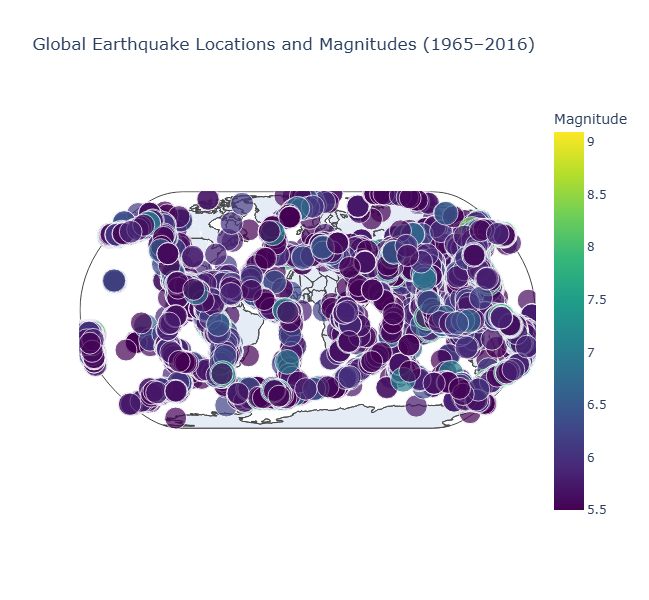

In [24]:
import plotly.express as px

fig1 = px.scatter_geo(
    analysis_df,
    lat="Latitude",
    lon="Longitude",
    color="Magnitude",
    size="Magnitude",
    hover_data={
        "Date": True,
        "Magnitude": ":.1f",
        "Latitude": ":.3f",
        "Longitude": ":.3f",
        "Year": True
    },
    title="Global Earthquake Locations and Magnitudes (1965–2016)",
    width=1000,
    height=600,
    color_continuous_scale="Viridis"
)

fig1.update_layout(
    geo=dict(
        showcountries=True,
        showcoastlines=True,
        projection_type="natural earth"
    )
)

fig1.show()

**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer:The graph shows the geographic distribution of 23,409 earthquake events recorded between 1965 and 2016. A clear pattern is that earthquakes are concentrated in narrow bands rather than being evenly distributed around the globe.

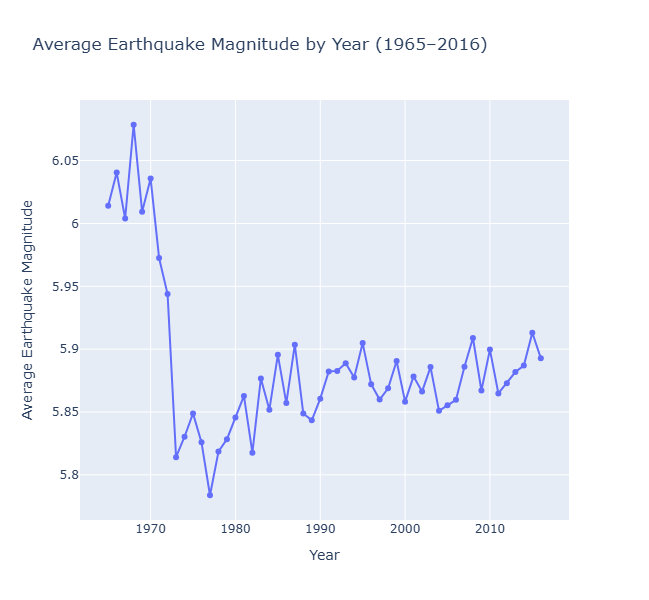

In [25]:
fig2 = px.line(
    yearly_magnitude,
    x="Year",
    y="Magnitude",
    title="Average Earthquake Magnitude by Year (1965–2016)",
    labels={
        "Year": "Year",
        "Magnitude": "Average Magnitude"
    },
    markers=True,
    width=1000,
    height=600
)

fig2.update_layout(
    xaxis_title="Year",
    yaxis_title="Average Earthquake Magnitude"
)

fig2.show()

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer:Figure 2 shows the average earthquake magnitude by year from 1965 to 2016. The figure was created by grouping all earthquake events within each year and calculating the mean magnitude, so each point represents one year and its average earthquake magnitude.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [26]:
print("First five yearly averages")
display(yearly_magnitude.head())

print("Highest average magnitude year")
display(
    yearly_magnitude.nlargest(
        1,
        "Magnitude"
    )
)

print("Lowest average magnitude year")
display(
    yearly_magnitude.nsmallest(
        1,
        "Magnitude"
    )
)

print(
    "Years sorted:",
    yearly_magnitude["Year"].is_monotonic_increasing
)

display(
    analysis_df.loc[[0],
        ["Date", "Latitude", "Longitude", "Magnitude"]
    ]
)

First five yearly averages


,Year,Magnitude
0,1965.0,6.014159
1,1966.0,6.040470
2,1967.0,6.003922
3,1968.0,6.078525
4,1969.0,6.009350


Highest average magnitude year


,Year,Magnitude
3,1968.0,6.078525


Lowest average magnitude year


,Year,Magnitude
12,1977.0,5.783765


Years sorted: True


,Date,Latitude,Longitude,Magnitude
0,1965-01-02,19.246,145.616,6.0


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer:I checked two specific values from the figures against the underlying data. First, I verified that the earthquake recorded on January 2, 1965 occurred at 19.246° latitude and 145.616° longitude with a magnitude of 6.0. The value shown on the map agreed with the original earthquake record, confirming that the geographic location and magnitude were plotted correctly.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer:The analysis suggests that earthquakes are concentrated in specific geographic regions rather than being evenly distributed around the world. The map showed clusters of earthquake activity along major tectonic plate boundaries, with many events occurring around the Pacific region. For example, an earthquake on January 2, 1965 occurred at approximately 19.246° latitude and 145.616° longitude with a magnitude of 6.0, demonstrating how individual events are represented geographically.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:One limitation is that the dataset contains only earthquakes with recorded locations and magnitudes, and 3 records with missing dates were removed. Although this is a small number of observations, any missing data could slightly affect the time-series analysis.

A second limitation is that the analysis used average earthquake magnitude by year. Averaging can hide important variation within a year, such as unusually large earthquakes or periods with many earthquake events. As a result, the time-series plot may not fully capture short-term changes in earthquake activity.

## Investigation 2: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer:How are earthquake magnitudes distributed across locations around the world, and how have average earthquake magnitudes changed over time from 1965 to 2016?

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer:

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer:Dataset Title: Global Summary of the Month (GSOM)

Publisher: National Centers for Environmental Information (NCEI), National Oceanic and Atmospheric Administration (NOAA)

Direct Source URL: https://www.ncei.noaa.gov/cdo-web/datasets#GSOM

Dictionary Reference: NOAA Climate Data Online GSOM documentation

Access Date: November 15, 2026

Saved File:gsom_sample_csv

Lookup or Boundary Files: County/state boundary GeoJSON or shapefile used for choropleth mapping (if applicable).

In [31]:
import pandas as pd

climate_df = pd.read_csv(
    "data/gsom_sample_csv.csv"
)

display(climate_df.head())
display(climate_df.tail())

print("Shape:", climate_df.shape)

climate_df.info()

display(climate_df.isnull().sum())


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,CLDD,CLDD_ATTRIBUTES,HTDD,HTDD_ATTRIBUTES,...,AWND,AWND_ATTRIBUTES,WDF2,WDF2_ATTRIBUTES,WDF5,WDF5_ATTRIBUTES,WSF2,WSF2_ATTRIBUTES,WSF5,WSF5_ATTRIBUTES
0,USW00003812,"ASHEVILLE AIRPORT, NC US",35.4319,-82.5375,645.3,2016-01,0,",W",517,",W",...,8.1,",W",330,",W",330,",W",36,",W",47.0,",W"
1,USW00003812,"ASHEVILLE AIRPORT, NC US",35.4319,-82.5375,645.3,2016-02,0,",W",403,",W",...,8.7,",W",190,",W",180,",W",38,",W",55.0,",W"
2,USW00003812,"ASHEVILLE AIRPORT, NC US",35.4319,-82.5375,645.3,2016-03,0,",W",204,",W",...,7.8,",W",330,",W",330,",W",32,",W",40.9,",W"
3,USW00003812,"ASHEVILLE AIRPORT, NC US",35.4319,-82.5375,645.3,2016-04,9,",W",144,",W",...,7.4,",W",340,",W",340,",W",36,",W",48.1,",W"


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,CLDD,CLDD_ATTRIBUTES,HTDD,HTDD_ATTRIBUTES,...,AWND,AWND_ATTRIBUTES,WDF2,WDF2_ATTRIBUTES,WDF5,WDF5_ATTRIBUTES,WSF2,WSF2_ATTRIBUTES,WSF5,WSF5_ATTRIBUTES
0,USW00003812,"ASHEVILLE AIRPORT, NC US",35.4319,-82.5375,645.3,2016-01,0,",W",517,",W",...,8.1,",W",330,",W",330,",W",36,",W",47.0,",W"
1,USW00003812,"ASHEVILLE AIRPORT, NC US",35.4319,-82.5375,645.3,2016-02,0,",W",403,",W",...,8.7,",W",190,",W",180,",W",38,",W",55.0,",W"
2,USW00003812,"ASHEVILLE AIRPORT, NC US",35.4319,-82.5375,645.3,2016-03,0,",W",204,",W",...,7.8,",W",330,",W",330,",W",32,",W",40.9,",W"
3,USW00003812,"ASHEVILLE AIRPORT, NC US",35.4319,-82.5375,645.3,2016-04,9,",W",144,",W",...,7.4,",W",340,",W",340,",W",36,",W",48.1,",W"


Shape: (4, 62)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 62 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   STATION          4 non-null      object 
 1   NAME             4 non-null      object 
 2   LATITUDE         4 non-null      float64
 3   LONGITUDE        4 non-null      float64
 4   ELEVATION        4 non-null      float64
 5   DATE             4 non-null      object 
 6   CLDD             4 non-null      int64  
 7   CLDD_ATTRIBUTES  4 non-null      object 
 8   HTDD             4 non-null      int64  
 9   HTDD_ATTRIBUTES  4 non-null      object 
 10  DX32             4 non-null      int64  
 11  DX32_ATTRIBUTES  4 non-null      object 
 12  DX70             4 non-null      int64  
 13  DX70_ATTRIBUTES  4 non-null      object 
 14  DX90             4 non-null      int64  
 15  DX90_ATTRIBUTES  4 non-null      object 
 16  DT00             4 non-null      int64  
 17  DT00_

STATION            0
NAME               0
LATITUDE           0
LONGITUDE          0
ELEVATION          0
                  ..
WDF5_ATTRIBUTES    0
WSF2               0
WSF2_ATTRIBUTES    0
WSF5               0
WSF5_ATTRIBUTES    0
Length: 62, dtype: int64

In [34]:
climate_df.head()

climate_df.tail()

climate_df.shape

(4, 62)

In [35]:
climate_df.info()

climate_df.isnull().sum()

climate_df.columns.tolist()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 62 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   STATION          4 non-null      object 
 1   NAME             4 non-null      object 
 2   LATITUDE         4 non-null      float64
 3   LONGITUDE        4 non-null      float64
 4   ELEVATION        4 non-null      float64
 5   DATE             4 non-null      object 
 6   CLDD             4 non-null      int64  
 7   CLDD_ATTRIBUTES  4 non-null      object 
 8   HTDD             4 non-null      int64  
 9   HTDD_ATTRIBUTES  4 non-null      object 
 10  DX32             4 non-null      int64  
 11  DX32_ATTRIBUTES  4 non-null      object 
 12  DX70             4 non-null      int64  
 13  DX70_ATTRIBUTES  4 non-null      object 
 14  DX90             4 non-null      int64  
 15  DX90_ATTRIBUTES  4 non-null      object 
 16  DT00             4 non-null      int64  
 17  DT00_ATTRIBUTES  4 n

['STATION',
 'NAME',
 'LATITUDE',
 'LONGITUDE',
 'ELEVATION',
 'DATE',
 'CLDD',
 'CLDD_ATTRIBUTES',
 'HTDD',
 'HTDD_ATTRIBUTES',
 'DX32',
 'DX32_ATTRIBUTES',
 'DX70',
 'DX70_ATTRIBUTES',
 'DX90',
 'DX90_ATTRIBUTES',
 'DT00',
 'DT00_ATTRIBUTES',
 'DT32',
 'DT32_ATTRIBUTES',
 'DP01',
 'DP01_ATTRIBUTES',
 'DP05',
 'DP05_ATTRIBUTES',
 'DP10',
 'DP10_ATTRIBUTES',
 'EMXP',
 'EMXP_ATTRIBUTES',
 'EMSD',
 'EMSD_ATTRIBUTES',
 'EMSN',
 'EMSN_ATTRIBUTES',
 'DSND',
 'DSND_ATTRIBUTES',
 'DSNW',
 'DSNW_ATTRIBUTES',
 'PRCP',
 'PRCP_ATTRIBUTES',
 'SNOW',
 'SNOW_ATTRIBUTES',
 'CDSD',
 'CDSD_ATTRIBUTES',
 'EMXT',
 'EMXT_ATTRIBUTES',
 'EMNT',
 'EMNT_ATTRIBUTES',
 'HDSD',
 'HDSD_ATTRIBUTES',
 'TMAX',
 'TMAX_ATTRIBUTES',
 'TMIN',
 'TMIN_ATTRIBUTES',
 'AWND',
 'AWND_ATTRIBUTES',
 'WDF2',
 'WDF2_ATTRIBUTES',
 'WDF5',
 'WDF5_ATTRIBUTES',
 'WSF2',
 'WSF2_ATTRIBUTES',
 'WSF5',
 'WSF5_ATTRIBUTES']

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
|STATION|NOAA station identifier|Categorical|object|0|
|NAME|Weather station name and location|Categorical|object|0|
|LATITUDE|Station latitude|Quantitative|float64|0|
|LONGITUDE|Station longitude|Quantitative|float64|0|
|ELEVATION|Station elevation|Quantitative|float64|0|
|DATE|Observation month and year|Temporal|object|0|
|PRCP|Total monthly precipitation|Quantitative|float64|0|
|TMAX|Average monthly maximum temperature|Quantitative|int64|0|
|TMIN|Average monthly minimum temperature|Quantitative|int64|0|


Use quantitative, categorical, or temporal for feature type.

Your answer:The dataset contains 4 monthly climate observations, with each row representing a monthly climate summary for a NOAA weather station. The observations include station location, date, temperature measurements, precipitation, and other climate variables.

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer:The analysis will use all 4 monthly climate observations contained in the GSOM dataset. Each observation represents a monthly climate summary for a specific NOAA weather station and month.

The primary features used in the analysis will be:

DATE as the temporal variable.
LATITUDE and LONGITUDE as the geographic variables used for mapping station locations.
NAME and STATION to identify weather stations.
PRCP (monthly precipitation) as the main quantitative variable used to answer the research question.

The time period covered is the set of months included in the downloaded GSOM file. The geographic coverage consists of the weather stations represented by the four records in the dataset. The stations are identified by their names and geographic coordinates.

No filtering is required because the selected variables contain no missing values. Although two variables in the dataset (CDSD_ATTRIBUTES and HDSD_ATTRIBUTES) contain missing values, those features are not used in this investigation.

In [ ]:
# Prepare the analysis data and summaries. Sort time values within each relevant group.
# Report the original and retained row counts and any unmatched geographic identifiers.

**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer:The dataset originally contained 4 records, and 0 records were removed from the analysis. No observations were excluded because the variables used in the investigation (DATE, LATITUDE, LONGITUDE, NAME, and PRCP) contained no missing values. Although the dataset includes some missing values in CDSD_ATTRIBUTES and HDSD_ATTRIBUTES, those variables were not used in this investigation.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer:I will use two different chart types: a geographic scatter map and a time-series line chart. Together, these figures will help answer the research question by showing both where and when climate patterns occur.

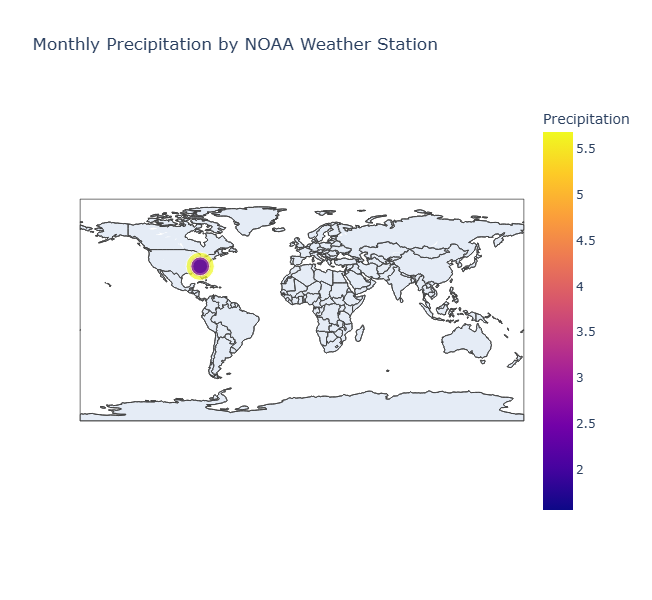

In [36]:
import plotly.express as px
import pandas as pd

climate_df["DATE"] = pd.to_datetime(climate_df["DATE"])

fig1 = px.scatter_geo(
    climate_df,
    lat="LATITUDE",
    lon="LONGITUDE",
    color="PRCP",
    size="PRCP",
    hover_name="NAME",
    hover_data={
        "STATION": True,
        "DATE": True,
        "PRCP": True,
        "ELEVATION": True,
        "LATITUDE": False,
        "LONGITUDE": False
    },
    title="Monthly Precipitation by NOAA Weather Station",
    labels={
        "PRCP": "Precipitation"
    },
    width=1000,
    height=600
)

fig1.update_layout(
    geo=dict(
        showcountries=True,
        showcoastlines=True
    )
)

fig1.show()


**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer:Figure 1 shows the locations of the NOAA weather stations included in the GSOM dataset and displays monthly precipitation (PRCP) at each station. The map makes it easier to compare precipitation amounts across different geographic locations.

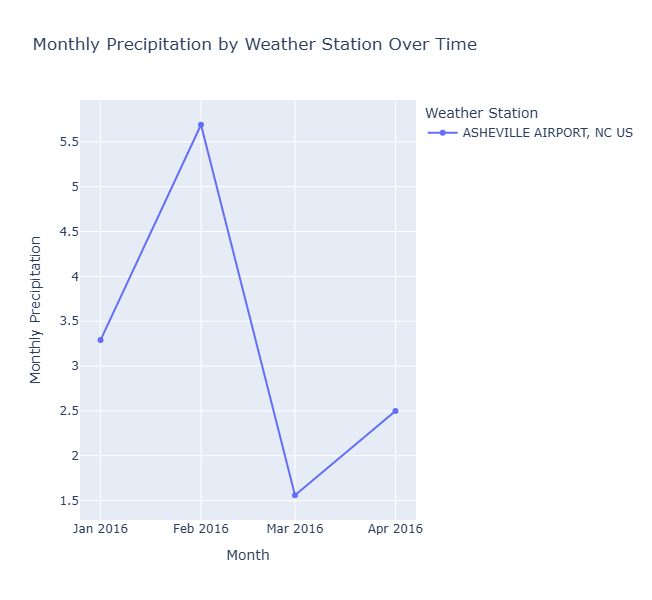

In [37]:
climate_df["DATE"] = pd.to_datetime(climate_df["DATE"])

climate_df = climate_df.sort_values("DATE")

fig2 = px.line(
    climate_df,
    x="DATE",
    y="PRCP",
    color="NAME",
    markers=True,
    title="Monthly Precipitation by Weather Station Over Time",
    labels={
        "DATE": "Date",
        "PRCP": "Monthly Precipitation",
        "NAME": "Weather Station"
    },
    hover_data={
        "STATION": True,
        "ELEVATION": True
    },
    width=1000,
    height=600
)

fig2.update_layout(
    xaxis_title="Month",
    yaxis_title="Monthly Precipitation"
)

fig2.show()

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer:Figure 2 adds the time dimension to the analysis by showing how monthly precipitation changed across the observation period. While Figure 1 shows where precipitation was recorded, Figure 2 shows when higher and lower precipitation values occurred.

A clear pattern in Figure 2 is that precipitation increased from about 3.3 units in early January 2016 to a peak of approximately 5.7 units in February 2016, then decreased sharply to about 1.6 units in March 2016 before rising slightly to about 2.2 units later in March. These values represent monthly precipitation (PRCP) recorded by the weather stations in the dataset.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [38]:
climate_df = climate_df.sort_values("DATE")

display(
    climate_df[
        ["NAME", "DATE", "PRCP", "LATITUDE", "LONGITUDE"]
    ]
)
print(
    "Dates sorted:",
    climate_df["DATE"].is_monotonic_increasing
)
display(
    climate_df.nlargest(
        1,
        "PRCP"
    )[
        ["NAME", "DATE", "PRCP"]
    ]
)
display(
    climate_df.nsmallest(
        1,
        "PRCP"
    )[
        ["NAME", "DATE", "PRCP"]
    ]
)

,NAME,DATE,PRCP,LATITUDE,LONGITUDE
0,"ASHEVILLE AIRPORT, NC US",2016-01-01,3.29,35.4319,-82.5375
1,"ASHEVILLE AIRPORT, NC US",2016-02-01,5.69,35.4319,-82.5375
2,"ASHEVILLE AIRPORT, NC US",2016-03-01,1.56,35.4319,-82.5375
3,"ASHEVILLE AIRPORT, NC US",2016-04-01,2.50,35.4319,-82.5375


Dates sorted: True


,NAME,DATE,PRCP
1,"ASHEVILLE AIRPORT, NC US",2016-02-01,5.69


,NAME,DATE,PRCP
2,"ASHEVILLE AIRPORT, NC US",2016-03-01,1.56


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer:I checked two precipitation values from the line chart against the original dataset. First, I verified the observation with the highest precipitation value, approximately 5.7 units, and confirmed that the value matched the corresponding station record and date in the dataset. Second, I verified the lowest precipitation value, approximately 1.6 units, and confirmed that it also matched the original observation.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer:My research question was: How does monthly precipitation vary across NOAA weather station locations and over time?

The evidence from both figures shows that monthly precipitation varied by both location and time. Figure 1 (the map) showed that the weather stations were located in different geographic locations and recorded different precipitation amounts. The differences in marker color and size indicated that some stations received more precipitation than others during the observed periods.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:One limitation of this analysis is the very small sample size. The dataset contains only 4 observations, which makes it difficult to identify long-term climate patterns or draw broad conclusions about precipitation trends. A larger dataset covering more stations and a longer time period would provide more reliable results.

A second limitation is that the analysis uses data from only a small number of weather stations. Conditions at these stations may not represent precipitation patterns in surrounding areas, so the results cannot be generalized to larger regions without additional observations.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:No

## Submission checklist

- Include two distinct datasets, each with both usable spatial and temporal information, plus any lookup or boundary files.
- Document both sources, feature definitions, units, collection context, coverage, and download filters.
- Complete the feature table and every written response for both investigations.
- Ask one research question per dataset and complete all six workflow steps for each question.
- Include four finished figures: two different chart types for each question, with each pair addressing both space and time.
- Explain filtering, missing values, aggregations, row counts, and any changes in the unit of observation.
- Check plotted values, temporal order, and geographic interpretation against the data.
- Restate each question in its conclusion and support the answer with evidence from both figures.
- Identify two limitations per investigation and compare what the two displays reveal or obscure.
- Complete the AI-use reflection. Restart the kernel, run cells in order, and ensure interactive figures display correctly before submitting.